In [ ]:
# Imports and Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import os

# Ensure local src directory is on path
sys.path.append(os.path.abspath(".."))

from src.population import (
    DistrictPopulation,
    LinearTrendForecaster,
    ExponentialCAGRForecaster,
    FibonacciRatioForecaster,
    validate_models,
    estimate_classrooms,
    bootstrap_residuals_pi
)

# Set seed for reproducibility
rng = np.random.default_rng(2026)

# Data Initialization
years = np.arange(2015, 2025)
districts_data = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso": [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu": [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Mbarara": [195, 202, 210, 218, 227, 236, 246, 257, 269, 282], # User-added
    "Jinja": [240, 245, 251, 258, 265, 272, 280, 289, 298, 308]    # User-added
}

districts = {name: DistrictPopulation(name, years, pops) for name, pops in districts_data.items()}
for d in districts.values():
    print(repr(d))

DistrictPopulation(name='Kampala', start_year=2015, end_year=2024, count=10)
DistrictPopulation(name='Wakiso', start_year=2015, end_year=2024, count=10)
DistrictPopulation(name='Gulu', start_year=2015, end_year=2024, count=10)
DistrictPopulation(name='Mbarara', start_year=2015, end_year=2024, count=10)
DistrictPopulation(name='Jinja', start_year=2015, end_year=2024, count=10)


In [7]:
# Descriptive Statistics & Variance Variance Explanation
stats_rows = []
for name, d in districts.items():
    st_stat = d.stats_statistics()
    np_stat_pop = d.stats_numpy(ddof=0)
    np_stat_sample = d.stats_numpy(ddof=1)
    
    stats_rows.append({
        "District": name,
        "Mean": st_stat["mean"],
        "Median": st_stat["median"],
        "stdev (stats)": round(st_stat["stdev"], 2),
        "Var (stats / ddof=1)": round(st_stat["variance"], 2),
        "Var (np default / ddof=0)": round(np_stat_pop["variance"], 2),
    })

df_stats = pd.DataFrame(stats_rows)
display(df_stats)

,District,Mean,Median,stdev (stats),Var (stats / ddof=1),Var (np default / ddof=0)
0,Kampala,1477.0,1460.0,206.40,42601.11,38341.00
1,Wakiso,1280.0,1260.0,245.09,60066.67,54060.00
2,Gulu,389.5,382.5,53.72,2885.83,2597.25
3,Mbarara,234.2,231.5,29.12,847.96,763.16
4,Jinja,270.6,268.5,22.96,527.16,474.44


In [8]:
# YoY Growth Rates and CAGR Analysis
growth_rows = []
for name, d in districts.items():
    cagr = d.compute_cagr()
    yoy_mean = float(np.mean(d.compute_yoy_growth()))
    growth_rows.append({
        "District": name,
        "CAGR (%)": round(cagr * 100, 2),
        "Mean YoY Growth (%)": round(yoy_mean * 100, 2)
    })

df_growth = pd.DataFrame(growth_rows).sort_values(by="CAGR (%)", ascending=False)
display(df_growth)
print(f"Fastest growing district in relative terms: {df_growth.iloc[0]['District']} with {df_growth.iloc[0]['CAGR (%)']}% CAGR.")

,District,CAGR (%),Mean YoY Growth (%)
1,Wakiso,6.47,6.47
0,Kampala,4.61,4.61
2,Gulu,4.61,4.61
3,Mbarara,4.18,4.18
4,Jinja,2.81,2.81


Fastest growing district in relative terms: Wakiso with 6.47% CAGR.


In [9]:
# Backtesting & Model Validation (2015-2021 Train, 2022-2024 Test)
selected_models = {}

for name, d in districts.items():
    print(f"\n--- Validation Results for {name} ---")
    df_res, best_m = validate_models(d.years, d.populations, split_year=2021)
    display(df_res)
    selected_models[name] = best_m
    print(f"Selected Best Model for {name}: {best_m}")


--- Validation Results for Kampala ---


,Model,MAE,RMSE,MAPE
0,Linear Trend,37.619048,38.974961,2.165173
1,Exponential CAGR,9.619128,10.385147,0.551460
2,Fibonacci Ratio,787.111111,792.161974,45.727194


Selected Best Model for Kampala: Exponential CAGR

--- Validation Results for Wakiso ---


,Model,MAE,RMSE,MAPE
0,Linear Trend,49.404762,52.367828,3.093815
1,Exponential CAGR,6.801562,8.049068,0.420107
2,Fibonacci Ratio,635.222222,640.430093,40.536806


Selected Best Model for Wakiso: Exponential CAGR

--- Validation Results for Gulu ---


...

Selected Best Model for Gulu: Exponential CAGR

--- Validation Results for Mbarara ---


,Model,MAE,RMSE,MAPE
0,Linear Trend,7.690476,8.358567,2.813497
1,Exponential CAGR,3.392125,3.842832,1.235918
2,Fibonacci Ratio,121.533333,122.310479,45.190197


Selected Best Model for Mbarara: Exponential CAGR

--- Validation Results for Jinja ---


,Model,MAE,RMSE,MAPE
0,Linear Trend,6.047619,6.465502,2.008660
1,Exponential CAGR,3.505027,3.846385,1.161939
2,Fibonacci Ratio,146.555556,147.432973,49.127606


Selected Best Model for Jinja: Exponential CAGR


In [10]:
# 2025-2029 Forecasting, Variance Comparison, and School Planning
model_map = {
    "Linear Trend": LinearTrendForecaster,
    "Exponential CAGR": ExponentialCAGRForecaster,
    "Fibonacci Ratio": FibonacciRatioForecaster
}

planning_rows = []
plt_data = {}

for name, d in districts.items():
    best_m_name = selected_models[name]
    model_cls = model_map[best_m_name]
    
    # Full fit and predict 5 steps (2025-2029)
    model = model_cls().fit(d.years, d.populations)
    future_years = np.arange(2025, 2030)
    forecasts, lower_pi, upper_pi = bootstrap_residuals_pi(model_cls, d.years, d.populations, horizon=5, seed=2026)
    
    fitted_vals = model.predict(len(d.years)) if not isinstance(model, LinearTrendForecaster) else model.slope * d.years + model.intercept
    
    # Variances
    var_actual = float(np.var(d.populations, ddof=1))
    var_forecast = float(np.var(forecasts, ddof=1))
    
    # School Planning (2024 to 2029 increase)
    pop_2024 = d.populations[-1]
    pop_2029 = forecasts[-1]
    increase_2029 = pop_2029 - pop_2024
    plan = estimate_classrooms(increase_2029)
    
    planning_rows.append({
        "District": name,
        "Best Model": best_m_name,
        "Var(Actual)": round(var_actual, 2),
        "Var(Forecast)": round(var_forecast, 2),
        "Pop 2024 (k)": pop_2024,
        "Pop 2029 Forecast (k)": round(pop_2029, 1),
        "Additional Pupils": int(plan["pupil_increase"]),
        "Classrooms Needed": plan["classrooms_needed"]
    })
    
    plt_data[name] = {
        "hist_years": d.years,
        "hist_pops": d.populations,
        "fitted_vals": fitted_vals,
        "future_years": future_years,
        "forecasts": forecasts,
        "lower_pi": lower_pi,
        "upper_pi": upper_pi
    }

df_planning = pd.DataFrame(planning_rows)
display(df_planning)

,District,Best Model,Var(Actual),Var(Forecast),Pop 2024 (k),Pop 2029 Forecast (k),Additional Pupils,Classrooms Needed
0,Kampala,Exponential CAGR,42601.11,21607.68,1800.0,2254.8,81857,1545
1,Wakiso,Exponential CAGR,60066.67,40131.36,1670.0,2284.7,110640,2088
2,Gulu,Exponential CAGR,2885.83,1536.55,480.0,601.3,21828,412
3,Mbarara,Exponential CAGR,847.96,428.23,282.0,346.1,11545,218
4,Jinja,Exponential CAGR,527.16,215.42,308.0,353.8,8241,156


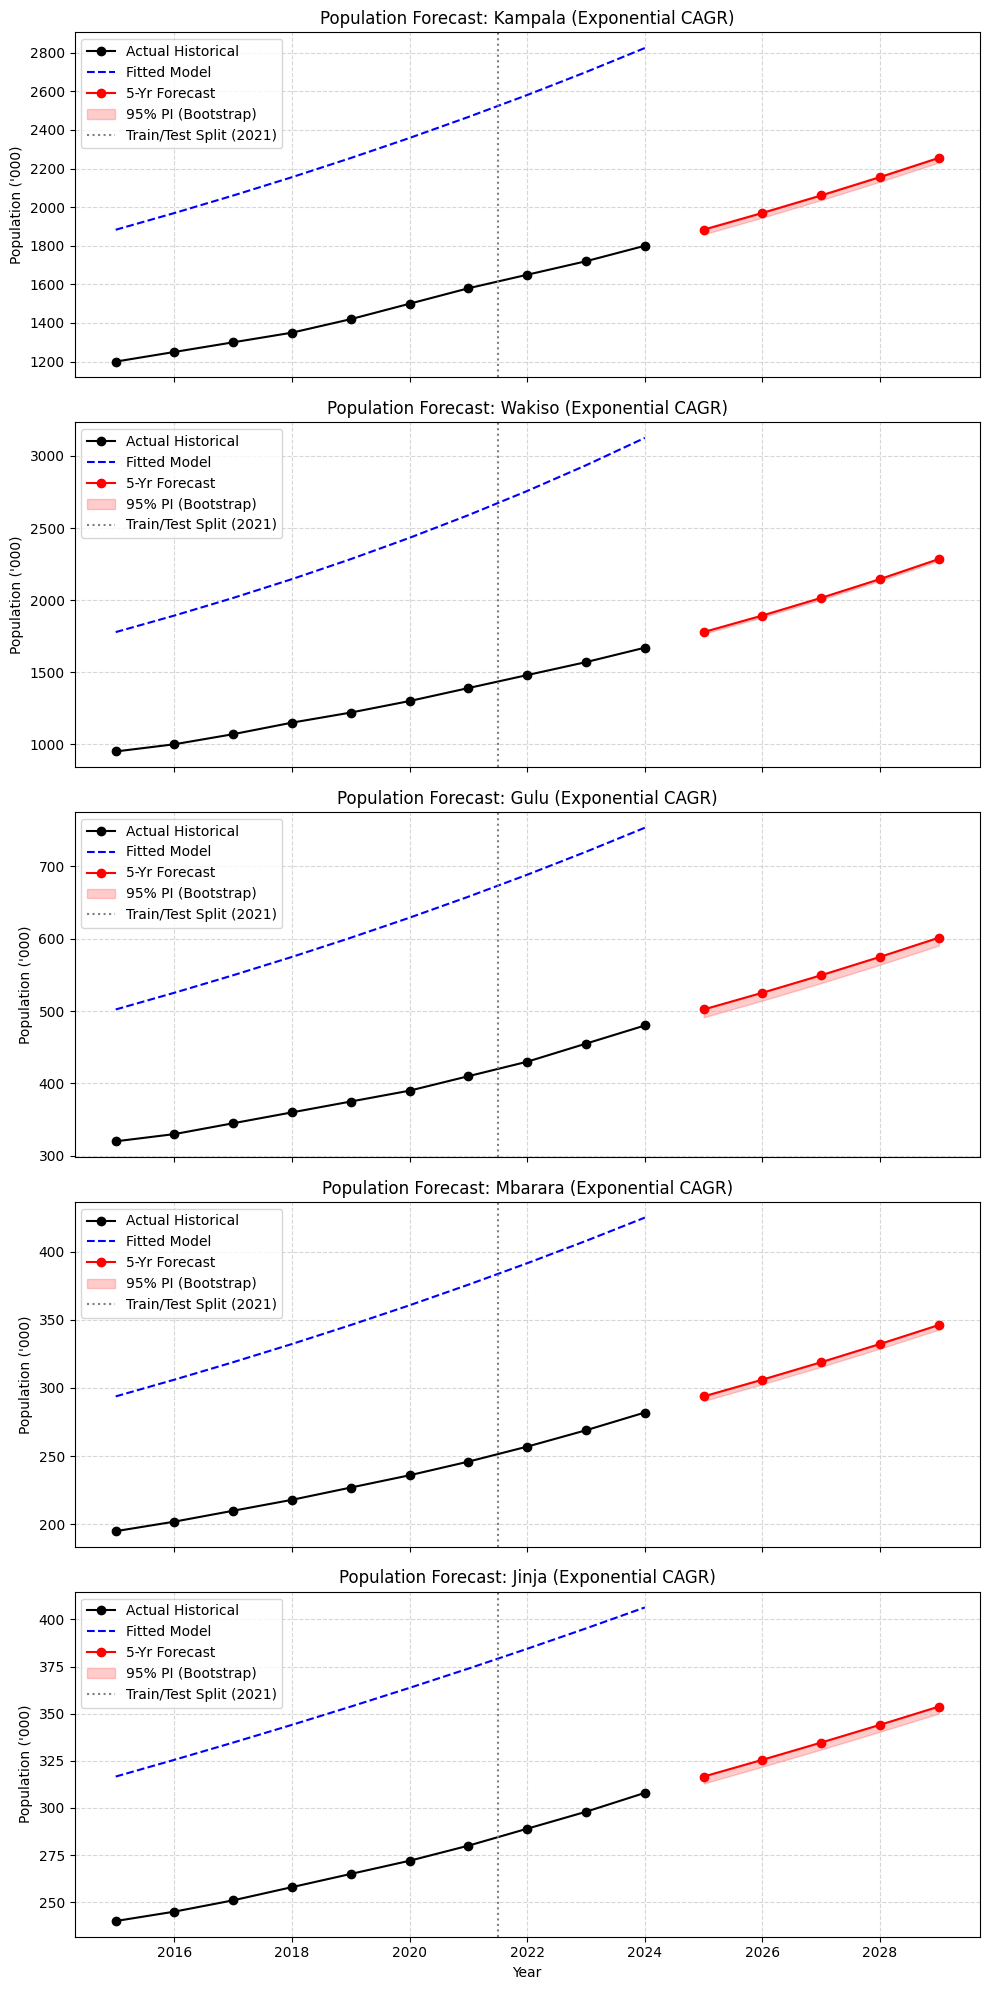

In [11]:
# Subplot Visualizations with Bootstrapped 95% CIs
fig, axes = plt.subplots(len(districts), 1, figsize=(10, 4 * len(districts)), sharex=True)

for ax, (name, data) in zip(axes, plt_data.items()):
    ax.plot(data["hist_years"], data["hist_pops"], 'ko-', label='Actual Historical')
    ax.plot(data["hist_years"], data["fitted_vals"], 'b--', label='Fitted Model')
    ax.plot(data["future_years"], data["forecasts"], 'ro-', label='5-Yr Forecast')
    ax.fill_between(data["future_years"], data["lower_pi"], data["upper_pi"], color='r', alpha=0.2, label='95% PI (Bootstrap)')
    
    ax.axvline(x=2021.5, color='gray', linestyle=':', label='Train/Test Split (2021)')
    ax.set_title(f"Population Forecast: {name} ({selected_models[name]})")
    ax.set_ylabel("Population ('000)")
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper left')

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()